# Late by Design · Predicting Late Order Lines

The companion Power BI report (*Late by Design*, an industrial parts distributor, Jan 2024 – Feb 2026) shows that **29% of shipped lines leave after the promised date**,
and that **backordered parts are late 3× as often** as parts in stock. A dashboard explains what *has* happened. This notebook asks what to do *before* a line goes late:

1. **Can we tell, on the day an order is entered, which lines will ship late?** Gradient-boosted trees (LightGBM), tested on months the model never saw.
2. **Why does the model flag a line?** SHAP values, for the whole book and for a single order line.
3. **Is lateness designed into the promise?** Comparing the promised lead time with the supplier's own lead time, and simulating a simple promise rule.

The cleaning rules are the same as in the Power BI model, so the numbers reconcile with the dashboard.

### Key Findings
* **Late lines can be predicted on the day of entry.** On six months the model never saw, LightGBM reaches **ROC AUC 0.82**, against 0.70 for the "is it a backorder?" rule. Flagging the riskiest **10%** of lines catches **30% of all late lines** with 84% precision. The riskiest **20%** catches **49%**.
* **Two facts drive most of the risk:** whether stock is on hand, and **how short the promise is.** New parts with little history, big multi-line orders and expensive items add some risk.
* **Lateness is largely designed into the promise.** **46% of backordered lines are promised faster than the supplier's own quoted lead time.** Those lines ship late 58–63% of the time, against 23% when the promise has a 30-day buffer. In stock, same-day promises are late 20% of the time, against 3% for promises of 30+ days.
* **A simple promise rule removes a fifth of lateness.** Never promising a backorder faster than the supplier's lead time cuts the late rate from **29.4% to 23.8%** with no change to how fast anything ships. The cost is longer promises on the 22% of lines that are re-promised.

In [1]:
# ---- where things live -------------------------------------------------------------------------
import os, sys
from pathlib import Path
os.environ.setdefault("LOKY_MAX_CPU_COUNT", str(os.cpu_count() or 1))   # silences a harmless joblib warning on Windows

MAIN_FOLDERS = [Path(r"C:\Users\Johanna\OneDrive\Documents\Portfolios\Radarr"),
                Path(r"C:\Users\Johanna\OneDrive\Documents\Portfolios\DPO&Co Test\Power BI Assessment")]
DATA_OVERRIDE = r""   # optional: full path of the raw .xlsx

def code_folder():
    for p in [Path.cwd(), *Path.cwd().parents]:
        if (p / "dpotools.py").exists():
            return p
    for root in [*MAIN_FOLDERS, Path.cwd()]:
        if root.exists():
            hits = sorted(root.rglob("dpotools.py"), key=lambda f: len(f.parts))
            if hits:
                return hits[0].parent
    return None

CODE = code_folder()
if CODE is None:
    raise FileNotFoundError("dpotools.py not found. Keep it next to this notebook.")
os.chdir(CODE)
sys.path.insert(0, str(CODE))
import dpotools as dt

DATA = Path(DATA_OVERRIDE) if DATA_OVERRIDE else dt.find_workbook(
    [CODE / "data", CODE, CODE.parent / "data", CODE.parent, *MAIN_FOLDERS, *[m / "data" for m in MAIN_FOLDERS]])
if DATA is None or not DATA.exists():
    raise FileNotFoundError("Raw workbook not found. Put the .xlsx in the data folder, or paste its full path into DATA_OVERRIDE.")

IMAGES = next((p for p in [CODE / "images", CODE.parent / "images"] if p.exists()), CODE / "images")
IMAGES.mkdir(exist_ok=True)

def save(fig, name):
    fig.savefig(IMAGES / f"{name}.png", dpi=150, bbox_inches="tight", facecolor="white")

print("Code:", CODE.name, "| Data:", DATA.name, "| Images:", IMAGES.name)

import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb
import shap
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, average_precision_score, brier_score_loss
from sklearn.calibration import calibration_curve
from dpotools import NAVY, BLUE, RED, AMBER, GREEN, PURPLE, SLATE, INK, MUTED, LINE

dt.style_charts()

Code: Late by Design Deep Dive | Data: PowerBI Assessment.xlsx | Images: images


## 1 · Same Data, Same Rules as the Dashboard

The raw promised delivery dates contain text dates, impossible years and 1899 placeholders. They are repaired exactly as in Power BI.
A line is **late** when it ships after the repaired promise date. **Backorder** means the stock was received after the order was entered.

In [2]:
lines = dt.load(DATA)
s = dt.scored(lines)
overdue = lines[lines.status == "Overdue (Not Shipped)"]
check = pd.Series({
    "Order lines in the extract": f"{len(lines):,}",
    "Lines scored (shipped, valid promise)": f"{len(s):,}",
    "Late rate": f"{s.late.mean():.1%}",
    "Median days late": f"{s.days_late.median():.0f}",
    "Backorder share of scored lines": f"{(s.stock_status == 'Backorder').mean():.0%}",
    "Late rate · backorder vs in stock": f"{s.late[s.stock_status == 'Backorder'].mean():.0%} vs {s.late[s.stock_status == 'In Stock'].mean():.0%}",
    "Open lines already overdue": f"{len(overdue):,} (${overdue.EXT_PRICE.sum() / 1e6:.1f}M)",
    "Promise dates repaired / missing": f"{(lines.promise_quality == 'Year Typo Fixed').sum()} / {(lines.promise_quality == 'Missing').sum()}",
}, name="value").to_frame()
check

,value
Order lines in the extract,"57,805"
"Lines scored (shipped, valid promise)","52,354"
Late rate,29.4%
Median days late,21
Backorder share of scored lines,48%
Late rate · backorder vs in stock,46% vs 15%
Open lines already overdue,"1,668 ($10.5M)"
Promise dates repaired / missing,29 / 155


## 2 · A Fair Test: Only What is Known at Order Entry, Scored on Unseen Months

* **Features** are limited to what the business knows when the order is keyed in: supplier, product line and type, stock category, regions and channel,
  order type, sourcing, buy plan, whether stock is on hand, the promised lead time, the supplier's quoted lead time, quantity, unit price,
  entry month and weekday, lines in the same order, and how many earlier lines the part has had.
  Ship dates, receipt dates and days late are never used as inputs.
* **Time split:** the model is trained on lines entered **Jan 2024 – Mar 2025** and tested on **Apr – Sep 2025**.
  Lines entered after September 2025 are left out, because many of their late lines have not shipped yet, which would make recent months look better than they are.

In [3]:
X = dt.features(s)
y = s.late
train = s.ENTRY_DATE < "2025-04-01"
test = (s.ENTRY_DATE >= "2025-04-01") & (s.ENTRY_DATE < "2025-10-01")
print(f"train: {train.sum():,} lines ({y[train].mean():.1%} late)   test: {test.sum():,} lines ({y[test].mean():.1%} late)")

model = lgb.LGBMClassifier(n_estimators=600, learning_rate=0.03, num_leaves=31, min_child_samples=40, subsample=0.8, subsample_freq=1,
                           colsample_bytree=0.8, reg_lambda=1.0, max_cat_to_onehot=8, cat_smooth=20, verbose=-1, random_state=0)
model.fit(X[train], y[train])
p = model.predict_proba(X[test])[:, 1]

# baselines: the single rule the dashboard suggests, and a regularised logistic regression
rule = (X.stock_status == "Backorder").astype(int)[test]
Xo = pd.get_dummies(X.drop(columns=["supplier"]), drop_first=True).fillna(0).astype(float)
logit = LogisticRegression(max_iter=3000, C=0.5).fit(Xo[train], y[train])
p_lr = logit.predict_proba(Xo[test])[:, 1]

def capture(scores, share):
    k = int(len(scores) * share)
    top = np.argsort(-scores)[:k]
    return y[test].values[top].sum() / y[test].sum()

results = pd.DataFrame({
    "model": ["Backorder flag only", "Logistic regression", "LightGBM"],
    "ROC AUC": [roc_auc_score(y[test], rule), roc_auc_score(y[test], p_lr), roc_auc_score(y[test], p)],
    "PR AUC": [average_precision_score(y[test], rule), average_precision_score(y[test], p_lr), average_precision_score(y[test], p)],
    "late lines caught in riskiest 20%": [np.nan, capture(p_lr, 0.2), capture(p, 0.2)],
})
results.style.hide(axis="index").format({"ROC AUC": "{:.3f}", "PR AUC": "{:.3f}", "late lines caught in riskiest 20%": "{:.0%}"}, na_rep="–")

train: 33,039 lines (31.5% late)   test: 12,973 lines (27.8% late)


  File "C:\Users\Johanna\anaconda3\lib\site-packages\joblib\externals\loky\backend\context.py", line 227, in _count_physical_cores
    cpu_info = subprocess.run(
  File "C:\Users\Johanna\anaconda3\lib\subprocess.py", line 505, in run
    with Popen(*popenargs, **kwargs) as process:
  File "C:\Users\Johanna\anaconda3\lib\subprocess.py", line 951, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "C:\Users\Johanna\anaconda3\lib\subprocess.py", line 1420, in _execute_child
    hp, ht, pid, tid = _winapi.CreateProcess(executable, args,


model,ROC AUC,PR AUC,late lines caught in riskiest 20%
Backorder flag only,0.701,0.406,–
Logistic regression,0.802,0.648,48%
LightGBM,0.821,0.689,49%


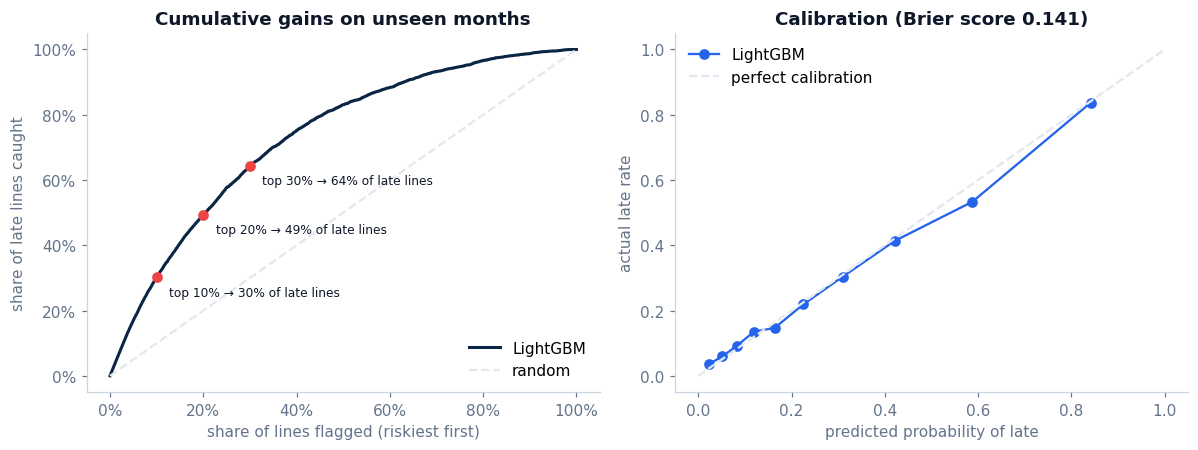

In [4]:
order = np.argsort(-p)
cum = np.cumsum(y[test].values[order]) / y[test].sum()
share = np.arange(1, len(p) + 1) / len(p)
frac_pos, mean_pred = calibration_curve(y[test], p, n_bins=10, strategy="quantile")

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
ax = axes[0]
ax.plot(share, cum, color=NAVY, lw=2, label="LightGBM")
ax.plot([0, 1], [0, 1], color=LINE, ls="--", label="random")
for q in (0.1, 0.2, 0.3):
    c = cum[int(q * len(p)) - 1]
    ax.scatter(q, c, color=RED, zorder=3)
    ax.annotate(f"top {q:.0%} → {c:.0%} of late lines", (q, c), xytext=(8, -12), textcoords="offset points", fontsize=8, color=INK)
ax.set_xlabel("share of lines flagged (riskiest first)"); ax.set_ylabel("share of late lines caught")
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}")); ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_title("Cumulative gains on unseen months"); ax.legend(frameon=False, loc="lower right")

ax = axes[1]
ax.plot(mean_pred, frac_pos, marker="o", color=BLUE, label="LightGBM")
ax.plot([0, 1], [0, 1], color=LINE, ls="--", label="perfect calibration")
ax.set_xlabel("predicted probability of late"); ax.set_ylabel("actual late rate")
ax.set_title(f"Calibration (Brier score {brier_score_loss(y[test], p):.3f})"); ax.legend(frameon=False)
plt.tight_layout(); save(fig, "model performance"); plt.show()

**Reading the results**
* **LightGBM beats both baselines** on unseen months: ROC AUC 0.82 vs 0.80 for logistic regression and 0.70 for the backorder flag alone. Its PR AUC of 0.69 is 2.5× the 28% base rate.
* **Ranking works.** The riskiest 10% of lines are late 84% of the time and hold 30% of all late lines. The riskiest 30% hold 64%. That is a practical daily worklist for expediting or re-promising.
* **Calibration is close to the diagonal** (Brier score 0.141), so a predicted 40% really means about 40% of such lines ship late. Risk scores can therefore go straight into a "re-promise if risk > x" rule.

## 3 · Why the Mmodel Flags a Line (SHAP)

SHAP splits every prediction into contributions from each feature, in log-odds of being late.
The beeswarm shows one dot per test line. Red dots have a high feature value and blue dots a low one, and dots to the right push toward *late*.

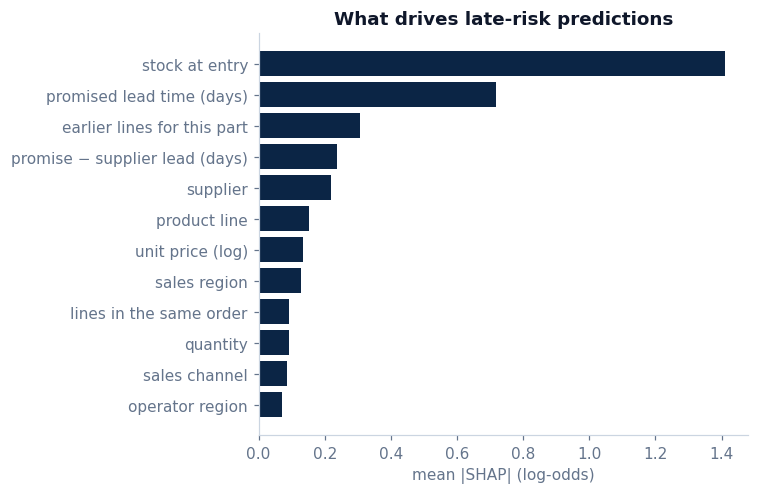

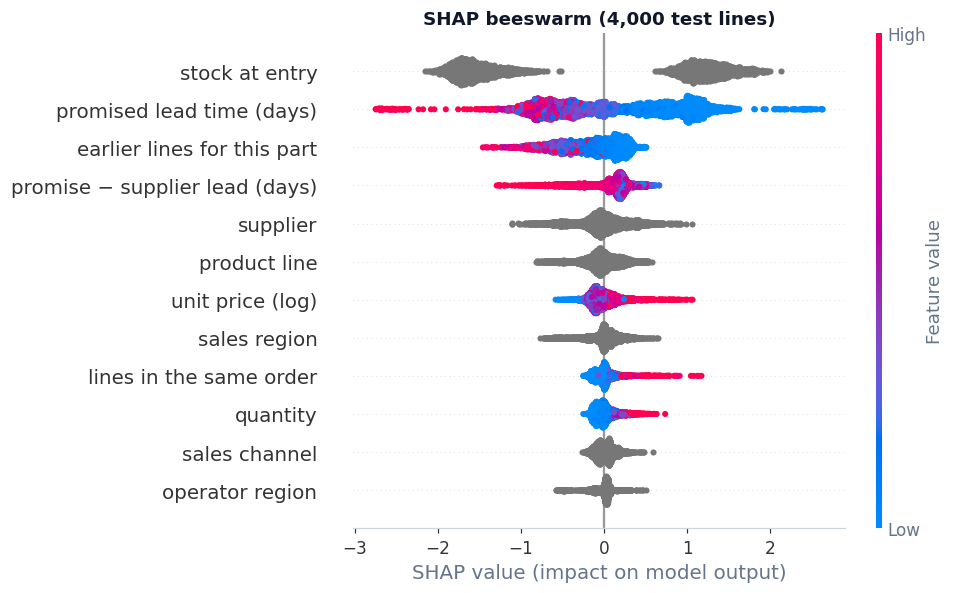

In [5]:
explainer = shap.TreeExplainer(model)
Xt = X[test]
sv = explainer.shap_values(Xt)
sv = sv[1] if isinstance(sv, list) else sv
Xt_named = Xt.rename(columns=dt.LABELS)

importance = pd.Series(np.abs(sv).mean(axis=0), index=Xt_named.columns).sort_values(ascending=True).tail(12)
fig, ax = plt.subplots(figsize=(7, 4.6))
ax.barh(importance.index, importance.values, color=NAVY)
ax.set_xlabel("mean |SHAP| (log-odds)"); ax.set_title("What drives late-risk predictions")
plt.tight_layout(); save(fig, "shap importance"); plt.show()

sample = np.random.RandomState(0).choice(len(Xt), size=min(4000, len(Xt)), replace=False)
shap.summary_plot(sv[sample], Xt_named.iloc[sample], max_display=12, show=False, plot_size=(9, 5.5))
fig = plt.gcf(); fig.axes[0].set_title("SHAP beeswarm (4,000 test lines)")
plt.tight_layout(); save(fig, "shap beeswarm"); plt.show()

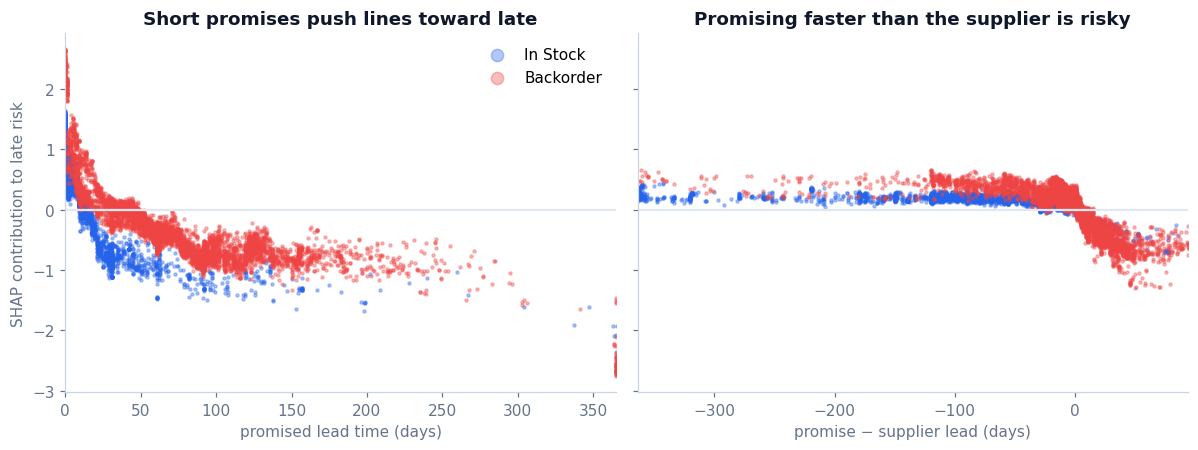

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True)
for ax, feat, label in [(axes[0], "promised_lead_days", "promised lead time (days)"), (axes[1], "promise_gap", "promise − supplier lead (days)")]:
    j = list(Xt.columns).index(feat)
    for status, colr in [("In Stock", BLUE), ("Backorder", RED)]:
        mask = (Xt.stock_status == status).values
        ax.scatter(Xt[feat].values[mask], sv[mask, j], s=4, alpha=0.35, color=colr, label=status)
    ax.axhline(0, color=LINE)
    ax.set_xlabel(label)
    ax.set_xlim(np.nanpercentile(Xt[feat], 1), np.nanpercentile(Xt[feat], 99))
axes[0].set_ylabel("SHAP contribution to late risk"); axes[0].legend(frameon=False, markerscale=4)
axes[0].set_title("Short promises push lines toward late"); axes[1].set_title("Promising faster than the supplier is risky")
plt.tight_layout(); save(fig, "shap promise dependence"); plt.show()

**Reading the SHAP Charts**
* **Stock at entry dominates**, as the dashboard suggested. Its average impact is 1.4 log-odds, twice that of any other feature.
* **The promised lead time is the second driver,** and the lever the business controls. Very short promises push risk up: the first days for in-stock lines, and the first 3–4 weeks for backorders. Long promises pull it down.
* **Promising faster than the supplier adds risk.** When the promise is shorter than the supplier's quoted lead time (left of 0 in the right-hand chart), the contribution turns positive.
* Smaller effects: **new parts** (no earlier lines: +0.25) are riskier than well-known ones (50+ earlier lines: −0.58). **Orders with 10+ lines** add +0.36, and the most expensive items add +0.18.
* **One line, explained:** a silicone seal from Supplier 304 was **backordered**, **promised for the same day**, and the supplier quotes **112 days**. The model gave it a 99% risk, and it shipped 129 days late. Nothing about this line was a surprise at entry.

### One Order Line, Explained

The riskiest line in the test months that really did ship late. The waterfall shows how each fact about it moves the prediction away from the average line.

Line 2072653129: SEAL ACCESS DOOR,NBR · Supplier 304 · Backorder · promised 0 days (supplier quotes 112 days) → predicted risk 99%, shipped 59 days late


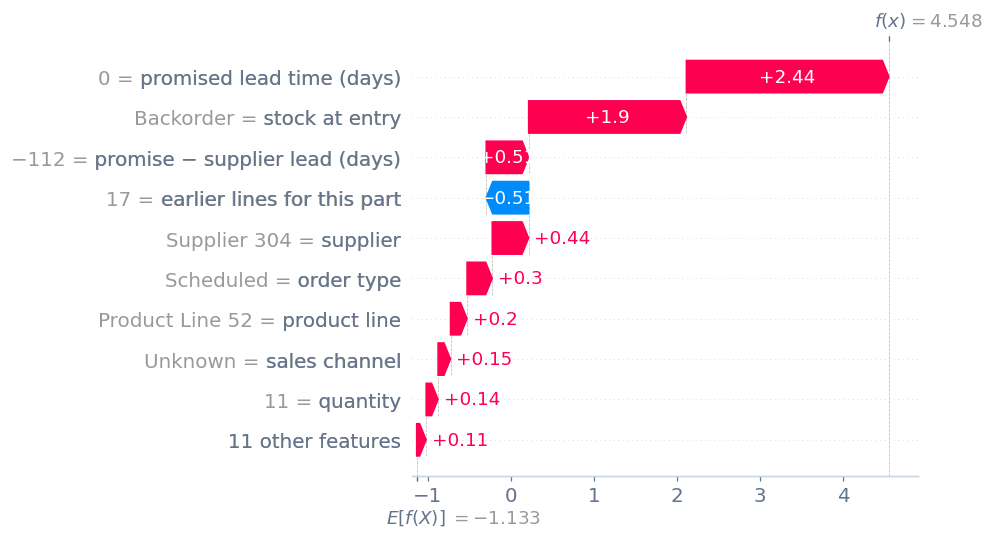

In [7]:
risky = np.where(y[test].values == 1)[0][np.argmax(p[y[test].values == 1])]
row = s[test].iloc[risky]
print(f"Line {row.Id}: {row.DESCRIPTION} · {row.MFG_NAME} · {row.stock_status} · promised {row.promised_lead_days:.0f} days "
      f"(supplier quotes {row.LEAD_DAYS} days) → predicted risk {p[risky]:.0%}, shipped {row.days_late:.0f} days late")
exp = shap.Explanation(values=sv[risky], base_values=explainer.expected_value if np.ndim(explainer.expected_value) == 0 else explainer.expected_value[1],
                       data=Xt_named.iloc[risky].values, feature_names=list(Xt_named.columns))
shap.plots.waterfall(exp, max_display=10, show=False)
fig = plt.gcf(); fig.set_size_inches(9, 5)
plt.tight_layout(); save(fig, "shap one line"); plt.show()

## 4 · Is Lateness Designed Into the Promise?

The dashboard's title is a hypothesis: lines are late *by design*. If the promise is shorter than the time the supplier itself needs, the line is late before it ships.

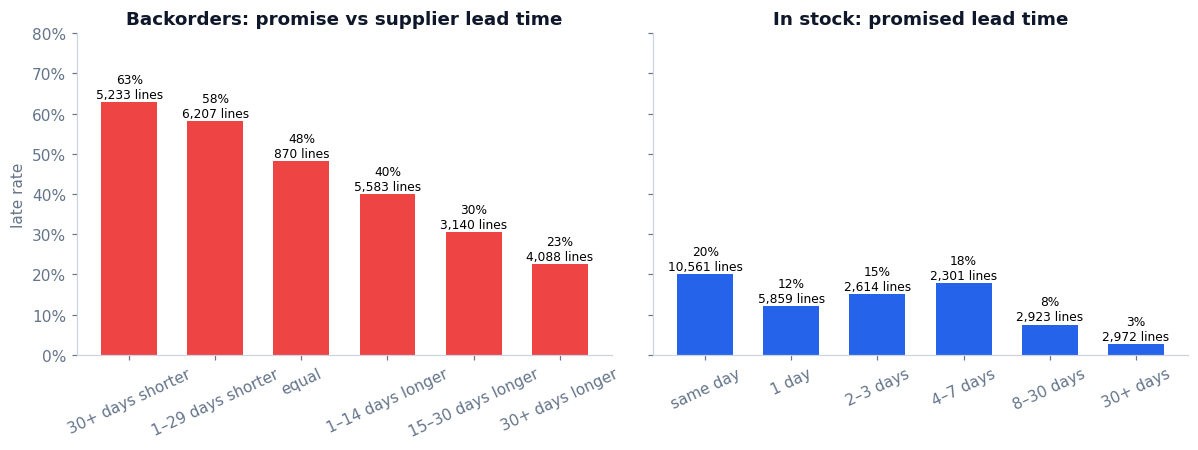

Backorder lines promised faster than the supplier's own lead time: 46%


In [8]:
s["promise_gap"] = s.promised_lead_days - s.LEAD_DAYS
bo = s[s.stock_status == "Backorder"]
gap_bands = pd.cut(bo.promise_gap, [-10000, -30, -1, 0, 14, 30, 10000],
                   labels=["30+ days shorter", "1–29 days shorter", "equal", "1–14 days longer", "15–30 days longer", "30+ days longer"])
by_gap = bo.groupby(gap_bands).agg(lines=("late", "size"), late=("late", "mean"))

ins = s[s.stock_status == "In Stock"]
lead_bands = pd.cut(ins.promised_lead_days, [-1, 0, 1, 3, 7, 30, 10000], labels=["same day", "1 day", "2–3 days", "4–7 days", "8–30 days", "30+ days"])
by_lead = ins.groupby(lead_bands).agg(lines=("late", "size"), late=("late", "mean"))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True)
for ax, tbl, colr, title in [(axes[0], by_gap, RED, "Backorders: promise vs supplier lead time"),
                             (axes[1], by_lead, BLUE, "In stock: promised lead time")]:
    ax.bar(tbl.index.astype(str), tbl.late, color=colr, width=0.65)
    for i, (v, n) in enumerate(zip(tbl["late"], tbl["lines"])):
        ax.text(i, v + 0.01, f"{v:.0%}\n{int(n):,} lines", ha="center", fontsize=8)
    ax.set_title(title); ax.tick_params(axis="x", rotation=25)
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
axes[0].set_ylabel("late rate"); axes[0].set_ylim(0, 0.8)
plt.tight_layout(); save(fig, "late by design"); plt.show()
print(f"Backorder lines promised faster than the supplier's own lead time: {(bo.promise_gap < 0).mean():.0%}")

### Simulating a Promise Rule

Rule: *never promise a backordered line faster than the supplier's lead time plus a buffer.* Actual ship dates are kept as they are, and only the promise moves.
This shows how much lateness is self-inflicted, and what it costs in longer promises.

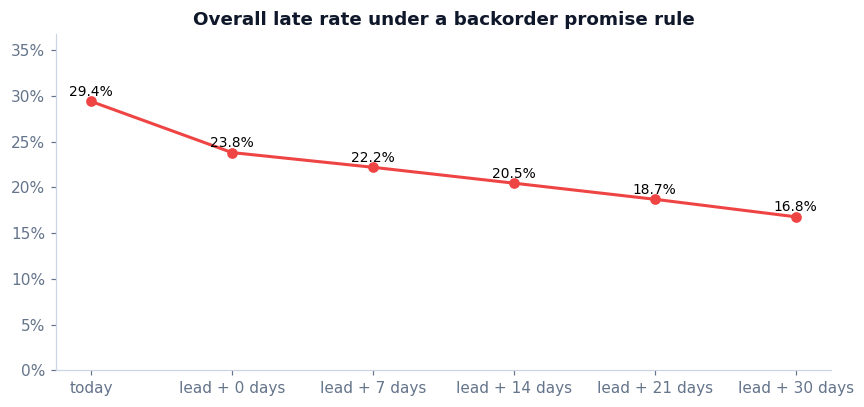

backorder promise rule,late rate,lines re-promised,avg extra days on re-promised lines
today,29.4%,0%,0
lead + 0 days,23.8%,22%,54
lead + 7 days,22.2%,29%,46
lead + 14 days,20.5%,34%,47
lead + 21 days,18.7%,37%,49
lead + 30 days,16.8%,40%,55


In [9]:
rows = []
is_bo = s.stock_status == "Backorder"
for buffer in [None, 0, 7, 14, 21, 30]:
    if buffer is None:
        new_promise = s.promised_lead_days
    else:
        new_promise = np.where(is_bo, np.maximum(s.promised_lead_days, s.LEAD_DAYS + buffer), s.promised_lead_days)
    late_new = s.processing_days > new_promise
    changed = new_promise != s.promised_lead_days
    rows.append(("today" if buffer is None else f"lead + {buffer} days", late_new.mean(),
                 changed.mean(), (new_promise - s.promised_lead_days)[changed].mean() if changed.any() else 0))
policy = pd.DataFrame(rows, columns=["backorder promise rule", "late rate", "lines re-promised", "avg extra days on re-promised lines"])

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(policy["backorder promise rule"], policy["late rate"], marker="o", color=RED, lw=2)
for i, v in enumerate(policy["late rate"]):
    ax.text(i, v + 0.006, f"{v:.1%}", ha="center", fontsize=9)
ax.set_ylim(0, policy["late rate"].max() * 1.25)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_title("Overall late rate under a backorder promise rule")
plt.tight_layout(); save(fig, "promise rule"); plt.show()
policy.style.hide(axis="index").format({"late rate": "{:.1%}", "lines re-promised": "{:.0%}", "avg extra days on re-promised lines": "{:.0f}"})

**Reading the Simulation**
* Today **46% of backordered lines** are promised faster than the supplier's own lead time. Their late rate (58–63%) is the main reason backorders look three times worse than stock.
* Simply **matching the supplier's lead time** (lead + 0) drops the overall late rate from **29.4% to 23.8%**, about a fifth fewer late lines, while every part ships exactly when it did. Adding a 14-day buffer brings it to 20.5%.
* The trade-off is honest: re-promised lines get about 7–8 weeks more on their promise. A middle path is to apply the rule only to lines the model scores as high risk, and keep short promises where the model is confident.

## 5 · Where to Act First

Average predicted risk and actual late lines by supplier in the test months. It is the same "concentration" story as the dashboard, now ranked by expected lateness *before* shipping.

In [10]:
risk = s[test].assign(risk=p)
sup = (risk.groupby("MFG_NAME").agg(lines=("late", "size"), predicted_risk=("risk", "mean"), actual_late=("late", "mean"),
                                    late_lines=("late", "sum"), backorder_share=("stock_status", lambda x: (x == "Backorder").mean()))
           .query("lines >= 100").sort_values("late_lines", ascending=False).head(10))
sup.index.name = "supplier"
sup.style.format({"lines": "{:,}", "predicted_risk": "{:.0%}", "actual_late": "{:.0%}", "late_lines": "{:,}", "backorder_share": "{:.0%}"})

,lines,predicted_risk,actual_late,late_lines,backorder_share
supplier,,,,,
Supplier 63,"1,489",42%,43%,635,60%
Supplier 26,"1,640",26%,26%,434,54%
Supplier 11,"1,344",28%,26%,347,48%
Supplier 36,865,32%,33%,284,71%
Supplier 34,"1,023",20%,22%,220,36%
Supplier 70,548,26%,27%,150,80%
Supplier 288,296,35%,39%,115,61%
Supplier 17,278,28%,35%,98,81%
Supplier 6,957,10%,8%,81,15%


## 6 · What This Adds to the Dashboard

| Dashboard says | Notebook adds |
|---|---|
| 29% of shipped lines are late; backorders are late 3× as often | Lateness can be **predicted at entry** (AUC 0.82 on unseen months). The riskiest 20% of lines hold half of all late lines. |
| Backordered parts are promised about 81 days while suppliers quote about 88 | Line by line, **46% of backorders are promised faster than the supplier quotes**, and those lines are late 58–63% of the time. |
| 10 suppliers cause 66% of late lines; Supplier 63 is late 43% of the time | The model ranks suppliers **before shipping**. Supplier 63's predicted risk (42%) matches its actual late rate (43%), so it can be managed proactively. |
| Late lines earn slightly lower margin | A **promise rule** alone would cut lateness by about a fifth with no operational change. |

**Recommendations**
1. **Never promise a backorder faster than the supplier's quoted lead time.** Add a buffer for high-risk suppliers.
2. **Score every new line at entry** and send the top 10–20% to an expediting or re-promise worklist.
3. **Review same-day promises on in-stock lines.** One in five still ships late. A one-day promise is late less often (12%).
4. **Feed the predicted risk back into Power BI** as a column, so the dashboard shows tomorrow's late lines, not only yesterday's.

### Limitations
* "In stock" uses the receipt date of the stock that was shipped. That is a good proxy for stock on hand at entry, but not a live inventory snapshot.
* Supplier and customer are paired 1:1 in this anonymised extract, so supplier effects may partly be customer effects.
* The promise simulation keeps ship dates fixed. In reality, a longer promise could change customer behaviour or prioritisation.